# 4. Baselines and honest splits

Two habits do more for the credibility of an ML result than any model trick:

1. **Build the strongest simple baseline you can**, and tune it as carefully as the model.
2. **Test on data the method has never seen in any form**: not its training data, and not the
   data you used to choose its settings.

This notebook sets up both, and shows how badly things go when (2) is skipped.

In [1]:
from hlw.nb import BLUE, GREEN, GREY, ORANGE, setup

setup()
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hlw import config as C

cfg = C.load_config()

## Splitting by lake *and* by time

Satellite pixels are not independent. Two pixels 10 m apart, or the same pixel on two dates a
week apart, are nearly copies of each other. If you split them at random into train and test,
the test set is full of near-duplicates of training data, and the score tells you very little
about a *new* lake or a *new* year.

So the splits here are by **lake** and by **year**:

In [2]:
rows = []
for fold, v in cfg["folds"].items():
    for k, lake in C.lakes().items():
        role = "TEST lake" if k == v["test_lake"] else "train lake"
        rows.append({"fold": fold, "lake": lake.name,
                     f"{cfg['train_years'][0]}-{cfg['train_years'][-1]}":
                     "evaluation only" if role == "TEST lake" else "training",
                     f"{cfg['test_years'][0]}-{cfg['test_years'][-1]}": "evaluation only"})
pd.DataFrame(rows)

,fold,lake,2018-2023,2024-2026
0,holdout_travis,Lake Buchanan,training,evaluation only
1,holdout_travis,Inks Lake,training,evaluation only
2,holdout_travis,Lake LBJ,training,evaluation only
3,holdout_travis,Lake Marble Falls,training,evaluation only
4,holdout_travis,Lake Travis,evaluation only,evaluation only
5,holdout_buchanan,Lake Buchanan,evaluation only,evaluation only
6,holdout_buchanan,Inks Lake,training,evaluation only
7,holdout_buchanan,Lake LBJ,training,evaluation only
8,holdout_buchanan,Lake Marble Falls,training,evaluation only
9,holdout_buchanan,Lake Travis,training,evaluation only


Each fold trains on four lakes in 2018-2023 and never sees the fifth. Travis and Buchanan, the
two lakes whose shorelines move, take turns as the held-out lake. The three small lakes are
always in training, but their 2024-2026 scenes are still unseen.

Results are reported for three groups of test points, from strictest to most lenient:

| group | lake seen in training? | year seen in training? |
|---|---|---|
| `heldout_lake_heldout_time` | no | no |
| `heldout_lake_train_time` | no | yes (other lakes, same years) |
| `train_lake_heldout_time` | yes | no |

and `all_heldout` pools all three. The strictest group is the closest to "deploy this on a lake
and a year it has never seen".

## The baselines

Every baseline must follow the same rules as the model, including for its settings:

* **Tuned cutoff**: for each test lake, choose the NDWI or MNDWI cutoff that maximises F1 on the
  hand-labelled points of the **other** lakes, in **training years only**. The test lake's
  labels never touch its own cutoff.
* **Otsu**: no tuning at all. Each scene picks its own cutoff from its own histogram
  (notebook 2). This is fully unsupervised and adapts to each date.

Here are the tuned cutoffs. Each row is tuned without that lake:

In [3]:
cuts = json.loads((C.RESULTS_DIR / "cutoffs.json").read_text())
pd.DataFrame([{"index": k.split(":")[0], "test lake": k.split(":")[1],
               "cutoff": round(v["cutoff"], 3), "F1 on dev points": round(v["dev_f1"], 3),
               "dev points": v["n_dev"]} for k, v in cuts.items()])

,index,test lake,cutoff,F1 on dev points,dev points
0,ndwi,travis,-0.060,1.000,188
1,ndwi,buchanan,-0.025,1.000,183
2,ndwi,inks,-0.025,1.000,297
3,ndwi,lbj,-0.025,1.000,299
4,ndwi,marble_falls,-0.025,1.000,297
5,mndwi,travis,-0.260,0.999,188
6,mndwi,buchanan,-0.140,0.986,183
7,mndwi,inks,-0.140,0.993,297
8,mndwi,lbj,-0.140,0.994,299
9,mndwi,marble_falls,-0.140,0.993,297


The tuned cutoffs barely change from lake to lake: about −0.03 for NDWI, close to the
textbook value of 0, and about −0.14 for MNDWI (−0.26 when Travis is held out). All of them
score F1 ≥ 0.99 on their tuning points. Now look at what happens on the test points.

In [4]:
m = pd.read_csv(C.RESULTS_DIR / "point_metrics.csv")
base = ["ndwi_tuned", "ndwi_otsu", "mndwi_tuned", "mndwi_otsu"]
groups = ["heldout_lake_heldout_time", "heldout_lake_train_time", "train_lake_heldout_time",
          "all_heldout"]
t = m[m.method.isin(base)].pivot_table(index="method", columns="group", values="iou")[groups]
t.round(3)

group,heldout_lake_heldout_time,heldout_lake_train_time,train_lake_heldout_time,all_heldout
method,,,,
mndwi_otsu,0.944,0.969,0.949,0.957
mndwi_tuned,0.928,0.948,0.949,0.939
ndwi_otsu,0.991,0.996,0.987,0.993
ndwi_tuned,0.991,0.996,0.997,0.994


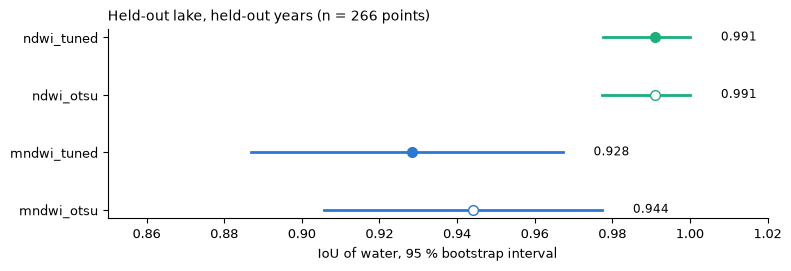

In [5]:
fig, ax = plt.subplots(figsize=(8, 2.8))
d = m[m.method.isin(base) & (m.group == "heldout_lake_heldout_time")].set_index("method").loc[base]
colors = [GREEN, GREEN, BLUE, BLUE]
for i, (meth, r) in enumerate(d.iterrows()):
    ax.plot([r.iou_lo, r.iou_hi], [i, i], color=colors[i], lw=2)
    ax.plot(r.iou, i, "o", color=colors[i], ms=7, mfc="white" if "otsu" in meth else colors[i])
    ax.text(r.iou_hi + 0.008, i, f"{r.iou:.3f}", va="center", fontsize=8.5)
ax.set_yticks(range(len(base)), base)
ax.set(xlabel="IoU of water, 95 % bootstrap interval", xlim=(0.85, 1.02),
       title=f"Held-out lake, held-out years (n = {int(d.n.iloc[0])} points)")
ax.invert_yaxis()
plt.tight_layout()

**NDWI travels; MNDWI slips a little.** Tuned NDWI scores 0.99 in every group: new lake, new
years, or both. MNDWI scores 0.93-0.95 on the same points. Otsu, which picks a cutoff per
scene with no labels at all, does as well as tuning for NDWI.

Why would the "modified" index, designed to improve on NDWI, do worse here? Two reasons:

* **Resolution.** NDWI uses green and near-infrared, both 10 m bands. MNDWI swaps NIR for
  short-wave infrared (B11), which Sentinel-2 records at 20 m. At a shoreline, each 20 m SWIR
  pixel blurs water and bank together, and the test here judges single 10 m pixels, mostly
  on the shoreline.
* **Bright water.** Some 2024-2026 scenes have very bright, turbid water (summer dates after
  rain). Its index values sit much closer to land. Look at the median index value of *water*
  points scene by scene:

In [6]:
pts = pd.read_csv(C.RESULTS_DIR / "points_scored.csv")
water = pts[pts.label == 1].groupby("scene")[["ndwi", "mndwi"]].median()
water["test year?"] = [int(s[-10:-6]) in cfg["test_years"] for s in water.index]
water.sort_values("ndwi").round(3).head(8)

,ndwi,mndwi,test year?
scene,,,
travis_2026-07-27,0.064,0.054,True
inks_2024-05-28,0.069,0.040,True
lbj_2024-05-18,0.117,0.100,True
buchanan_2026-07-27,0.184,0.201,True
inks_2018-03-26,0.311,0.330,False
marble_falls_2024-01-19,0.349,0.104,True
lbj_2020-10-06,0.363,0.425,False
travis_2023-10-16,0.446,0.352,False


On the brightest scenes, water's NDWI drops to 0.06-0.18, but that is still above a cutoff
near zero. So NDWI keeps that water.

### What the other answer key says

Scored against the AI answer key (notebook 3), the story is the opposite: tuned NDWI
"collapses" to IoU 0.65 on held-out dates, and you would conclude that "a cutoff on a
knife-edge doesn't travel". The cause is the labels, not NDWI.
The AI labeller had marked most hard shoreline pixels unsure. Tuning on the points that were
left put NDWI's cutoff at 0.23, on the shoulder of its distribution, and bright water fell
below it. With a person's labels, which commit on those shoreline pixels, the best cutoff is
about −0.03, and the collapse disappears.

The general lessons survive, sharpened:

* **A method's score on the data used to tune it means little.** Both cutoffs scored F1 0.99
  on their tuning points. Only held-out data told them apart.
* **Your labels choose your cutoff, and your cutoff can decide your verdict.** A tuned
  baseline inherits every bias of the labels it was tuned on.
* **Split by time as well as by place,** and report per-scene behaviour. There are only 18
  label scenes, so a handful of unusual dates can swing a group's score.

**Tuned NDWI, at about 0.99, is the baseline to beat.** It is one line of code, needs no GPU,
and is well understood. A deep model has to clear that bar on the same points to be worth its
cost.

## A note on the radar baseline

Sentinel-1 measures backscatter. Calm water reflects the radar pulse away from the satellite,
like a mirror, so it looks dark (low dB) in the VV channel. The classic radar baseline is the
same idea as NDWI: call a pixel water if VV is below a cutoff.

In [7]:
m[m.method.isin(["vv_tuned", "vv_otsu", "s1"])].pivot_table(index="method", columns="group",
                                                            values="iou")[groups].round(3)

group,heldout_lake_heldout_time,heldout_lake_train_time,train_lake_heldout_time,all_heldout
method,,,,
s1,0.933,0.965,0.940,0.948
vv_otsu,0.866,0.893,0.978,0.883
vv_tuned,0.869,0.852,0.991,0.866


The radar threshold is clearly weaker than the optical indices on held-out lakes (≈ 0.85-0.89). Wind roughens the
water surface and brightens it; smooth dry ground, roads and radar shadow behind hills can be
just as dark as water. The S1 U-Net (the `s1` row, explained in notebook 5) closes much of that
gap. That will turn out to be the clearest win for deep learning in the project.

## Takeaways

* Split by **lake and year**, never by random pixel.
* Tune every baseline's settings under the same rules as the model, and report it on the same
  held-out points.
* Be suspicious of any result that depends on a tuned setting, and check what the setting
  was tuned on. This project's NDWI result flipped from worst to best when the labels changed.

Next: [5 · the model](05_model.ipynb)